# **Notebook 1: Data Understanding & Exploratory Data Analysis**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED for this notebook:**
- [ ] `corporate_policies/` folder with `.md` SOP files uploaded to Colab:
  - `refund_policy.md`, `shipping_delays.md`, `password_reset.md`, `technical_troubleshooting.md`, `escalation_matrix.md`
- [ ] Internet access (to download Bitext dataset from HuggingFace)

**Files this notebook will CREATE:**
- [ ] `sampled_data.csv` — Cleaned, deduplicated, 4000-row sample of the Bitext dataset
  _(Required by: Notebook 2 — Data Preparation)_

> **Note:** Tasks 1.1 (Define Project Scope) and 1.4 (Design Methodology) are documented in your **Project Proposal PDF**, not this notebook. This notebook covers Tasks **1.2** and **1.3**.

---

## **Stage 1: Data Understanding & EDA**
### **Task 1.2: Understand and Assess Data**

#### **1.2.1 Inspect Dataset Structure [2 marks]**
**The Task:** Identify the presence of the corporate policy files within the local environment and successfully download the `bitext` customer support dataset from Hugging Face. Print the dataset information.

**Hints & Tips:**
* Use `glob` to find `.md` files in your workspace, and `load_dataset` for the bitext data.
* The dataset ID is `bitext/Bitext-customer-support-llm-chatbot-training-dataset` — it contains ~26,872 rows.
* Key columns: `instruction` (user query), `intent` (target class), `category` (broader group).

**Why we are doing it:** To ensure the local environment is properly configured with our knowledge base before reading data.
**How we are doing it:** Check the `corporate_policies` directory, load the dataset, and use `.info()`.

**Learner Inference:** If the files load correctly, your environment is stable. Seeing the 'intent' column confirms the target variable you will train your model to extract in Stage 4.

In [1]:
%pip install -q datasets

import os, glob, re, zipfile, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

# everything is kept on Drive so the next notebooks (and runtime restarts) can pick it up
from google.colab import drive
if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')
WORK_DIR = '/content/drive/MyDrive/hybrid_rag'
os.makedirs(WORK_DIR, exist_ok=True)
os.chdir(WORK_DIR)

# the SOPs come inside Dataset.zip
if not os.path.exists('Dataset.zip') and os.path.exists('/content/Dataset.zip'):
    shutil.copy('/content/Dataset.zip', 'Dataset.zip')
os.makedirs('corporate_policies', exist_ok=True)
with zipfile.ZipFile('Dataset.zip') as z:
    for name in z.namelist():
        if name.startswith('Dataset/sop_documents/') and name.endswith('.md'):
            with open(os.path.join('corporate_policies', os.path.basename(name)), 'wb') as f:
                f.write(z.read(name))

policy_files = sorted(glob.glob('corporate_policies/*.md'))
print(len(policy_files), 'SOP files found')
required = {'refund_policy.md', 'shipping_delays.md', 'password_reset.md',
            'technical_troubleshooting.md', 'escalation_matrix.md'}
assert required <= {os.path.basename(f) for f in policy_files}, 'a required SOP is missing'

sop_info = []
for f in policy_files:
    text = open(f, encoding='utf-8').read()
    lines = text.splitlines()
    sop_info.append({'file': os.path.basename(f), 'title': lines[0].lstrip('# '),
                     'has_h1': lines[0].startswith('# '),
                     'sections': sum(l.startswith('## ') for l in lines),
                     'words': len(text.split())})
display(pd.DataFrame(sop_info))

ds = load_dataset('bitext/Bitext-customer-support-llm-chatbot-training-dataset', split='train')
print(ds)
df_full = ds.to_pandas()
df_full.info()
display(df_full.head())

# completeness: nulls and empty strings per column
display(pd.DataFrame({'nulls': df_full.isnull().sum(),
                      'empty': (df_full.astype(str).apply(lambda c: c.str.strip()) == '').sum(),
                      'unique': df_full.nunique()}))

13 SOP files found


,file,title,has_h1,sections,words
0,account_recovery.md,Account Recovery,True,6,240
1,billing_disputes.md,Billing Disputes,True,6,250
2,data_privacy.md,Data Privacy,True,6,254
3,escalation_matrix.md,Escalation Matrix,True,5,234
4,order_tracking.md,Order Tracking,True,6,245
5,password_reset.md,Password Reset,True,6,258
6,payment_methods.md,Payment Methods,True,6,255
7,product_return.md,Product Return,True,7,243
8,refund_policy.md,Refund Policy,True,6,280
9,shipping_delays.md,Shipping Delays,True,5,247


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Dataset({
    features: ['flags', 'instruction', 'category', 'intent', 'response'],
    num_rows: 26872
})
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26872 entries, 0 to 26871
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   flags        26872 non-null  object
 1   instruction  26872 non-null  object
 2   category     26872 non-null  object
 3   intent       26872 non-null  object
 4   response     26872 non-null  object
dtypes: object(5)
memory usage: 1.0+ MB


,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


,nulls,empty,unique
flags,0,0,394
instruction,0,0,24635
category,0,0,11
intent,0,0,27
response,0,0,26870


#### **1.2.2 Quantify Dataset Characteristics [3 marks]**
**The Task:** Calculate the original size of the dataset, identify the number of unique intents, and randomly sample the dataset down to 4,000 rows.

**Hints & Tips:**
* Use `len()`, `.nunique()`, and `.sample(4000, random_state=42)`.
* `random_state=42` ensures reproducibility — everyone gets the same sample.
* With 4000 rows and 27 intents, you'll get ~148 examples per intent on average.

**Parameter Tuning:**
* `sample(n)` — try 1000–5000 per the workflow spec:
  - `1000`: Fast (~1 min), lower accuracy
  - `4000`: Moderate (~3 min), better accuracy (recommended)
  - `5000`: Slower, best accuracy, may hit T4 memory limits

**Learner Inference:** Capping at 4000 rows keeps your Stage 4 training loop to minutes while providing enough examples per intent.

Rows: 26872
Unique intents: 27
Unique categories: 11


,char_len,word_len,token_len
count,26872.0,26872.0,26872.0
mean,46.9,8.7,10.1
std,10.9,2.6,3.1
min,6.0,1.0,1.0
25%,40.0,7.0,8.0
50%,48.0,9.0,10.0
75%,55.0,11.0,12.0
max,92.0,16.0,24.0


Sample: 4000 rows, 27 intents, 115-169 rows per intent


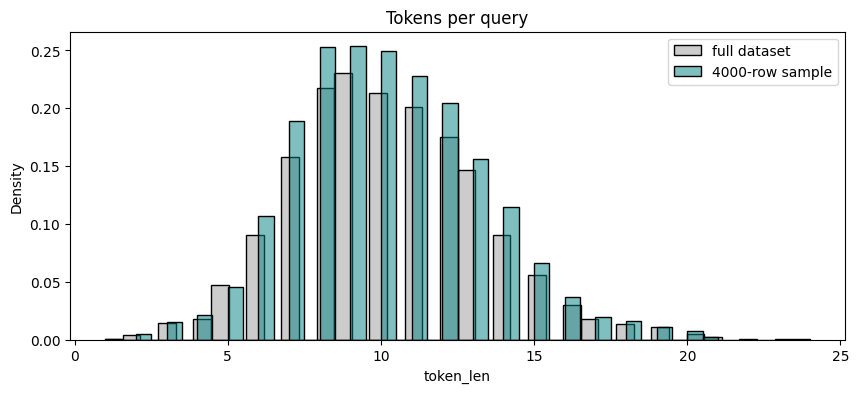

In [2]:
from transformers import AutoTokenizer

MODEL_ID = 'Qwen/Qwen2.5-1.5B-Instruct'
SEED = 42

print('Rows:', len(df_full))
print('Unique intents:', df_full['intent'].nunique())
print('Unique categories:', df_full['category'].nunique())

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
df_full['char_len'] = df_full['instruction'].str.len()
df_full['word_len'] = df_full['instruction'].str.split().str.len()
df_full['token_len'] = [len(x) for x in tokenizer(df_full['instruction'].tolist())['input_ids']]
display(df_full[['char_len', 'word_len', 'token_len']].describe().round(1))

df = df_full.sample(4000, random_state=SEED).reset_index(drop=True)
counts = df['intent'].value_counts()
print(f'Sample: {len(df)} rows, {df.intent.nunique()} intents, {counts.min()}-{counts.max()} rows per intent')
assert df['intent'].nunique() == df_full['intent'].nunique()

plt.figure(figsize=(10, 4))
sns.histplot(df_full['token_len'], bins=40, stat='density', color='grey', alpha=0.4, label='full dataset')
sns.histplot(df['token_len'], bins=40, stat='density', color='teal', alpha=0.5, label='4000-row sample')
plt.title('Tokens per query')
plt.legend()
plt.show()

#### **1.2.3 Validate Sample Quality [2 marks]**
**The Task:** Identify and remove records containing null values or duplicated customer instructions using normalised deduplication.

**Hints & Tips:**
* Use `.isnull().sum()` to check nulls.
* Simple `drop_duplicates` misses near-dupes like `"Where is my order?"` vs `"where is my order?"`.
* Normalise to lowercase + strip whitespace BEFORE deduplicating to catch these.
* The Bitext dataset typically has ~15 near-duplicates in a 4000-row sample.

**Learner Inference:** Cleaning now prevents "garbage-in, garbage-out". Duplicate prompts can cause leakage between train and test sets later.

In [3]:
cols = ['instruction', 'intent', 'category']
before = len(df)

print(df[cols].isnull().sum())
incomplete = df[cols].isnull().any(axis=1) | (df[cols].astype(str).apply(lambda c: c.str.strip()) == '').any(axis=1)
print('Incomplete rows:', incomplete.sum())

print('Extra whitespace in query:', df['instruction'].str.contains(r'^\s|\s$|\s{2,}').sum())
print('Intent not lowercase:', (df['intent'] != df['intent'].str.lower()).sum())
print('Category not uppercase:', (df['category'] != df['category'].str.upper()).sum())
print('Queries with {{placeholders}}:', df['instruction'].str.contains(r'\{\{.*?\}\}').sum())  # Bitext entity slots, kept

print('Exact duplicates:', df.duplicated('instruction').sum())
df['norm'] = df['instruction'].str.lower().str.strip()
print('Duplicates after lowercase + strip:', df.duplicated('norm').sum())

df = df[~incomplete].drop_duplicates('norm').drop(columns='norm').reset_index(drop=True)
print(f'{before} -> {len(df)} rows')
assert 1000 <= len(df) <= 5000

# prompt-solution alignment: every intent should sit under exactly one category
assert (df.groupby('intent')['category'].nunique() == 1).all()
display(df.groupby('category')['intent'].unique().to_frame())

instruction    0
intent         0
category       0
dtype: int64
Incomplete rows: 0
Extra whitespace in query: 79
Intent not lowercase: 0
Category not uppercase: 0
Queries with {{placeholders}}: 938
Exact duplicates: 83
Duplicates after lowercase + strip: 98
4000 -> 3902 rows


,intent
category,
ACCOUNT,"[delete_account, registration_problems, switch..."
CANCEL,[check_cancellation_fee]
CONTACT,"[contact_human_agent, contact_customer_service]"
DELIVERY,"[delivery_period, delivery_options]"
FEEDBACK,"[complaint, review]"
INVOICE,"[check_invoice, get_invoice]"
ORDER,"[cancel_order, change_order, track_order, plac..."
PAYMENT,"[payment_issue, check_payment_methods]"
REFUND,"[check_refund_policy, get_refund, track_refund]"


### **Task 1.3: Perform Exploratory Data Analysis**

#### **1.3.1 Perform Univariate Analysis [2 marks]**
**The Task:** Plot the top 10 most frequent customer intents using a horizontal bar chart.

**Hints & Tips:**
* Use a Seaborn `countplot` with `order=df['intent'].value_counts().index[:10]`.
* Check if any single intent dominates >80% of data — signals severe class imbalance.
* `palette="viridis"` works well for accessibility.

**Learner Inference:** This visual reveals class imbalance. If one intent dominates, your fine-tuned router becomes biased toward guessing it.

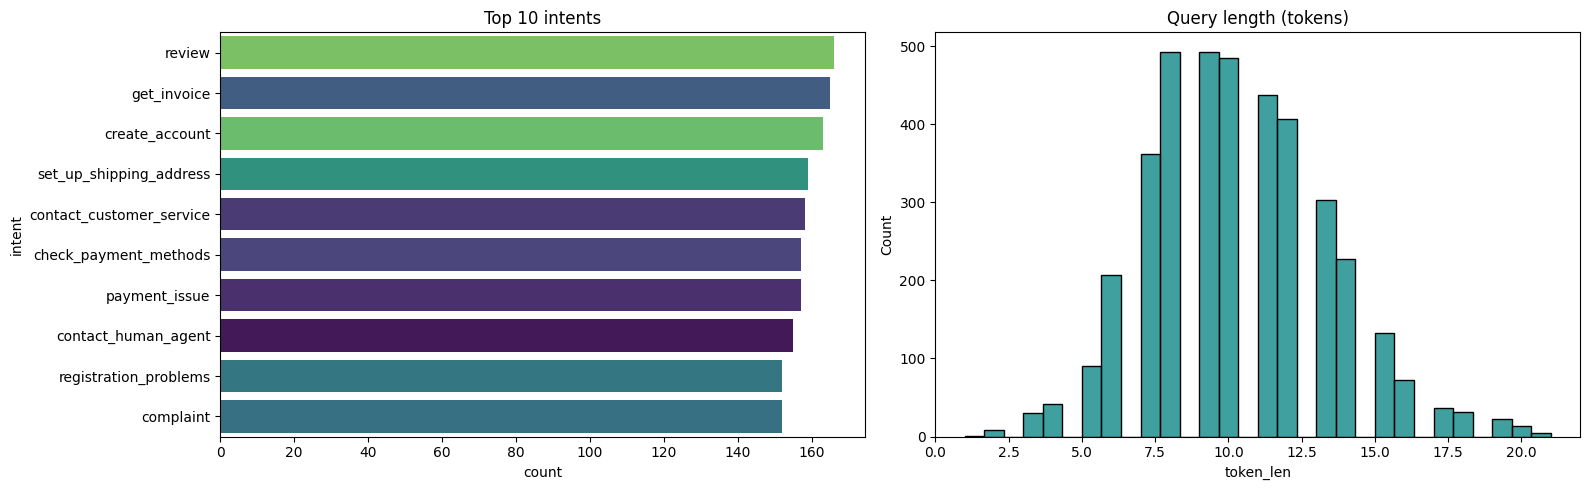

Largest intent: review (4.3%)
Smallest intent: cancel_order (108 rows)
Max/min ratio: 1.54
category
ACCOUNT         0.217
ORDER           0.132
REFUND          0.109
FEEDBACK        0.081
PAYMENT         0.080
CONTACT         0.080
INVOICE         0.080
SHIPPING        0.080
DELIVERY        0.074
CANCEL          0.036
SUBSCRIPTION    0.029
Name: proportion, dtype: float64


In [4]:
counts = df['intent'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.countplot(data=df, y='intent', order=counts.index[:10], hue='intent', palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('Top 10 intents')
sns.histplot(df['token_len'], bins=30, color='teal', ax=axes[1])
axes[1].set_title('Query length (tokens)')
plt.tight_layout()
plt.show()

print(f'Largest intent: {counts.index[0]} ({counts.iloc[0] / len(df):.1%})')
print(f'Smallest intent: {counts.index[-1]} ({counts.iloc[-1]} rows)')
print(f'Max/min ratio: {counts.max() / counts.min():.2f}')
print(df['category'].value_counts(normalize=True).round(3))

#### **1.3.2 Perform Bivariate Analysis [2 marks]**
**The Task:** Read the text from the uploaded Markdown SOP files and fit a `TfidfVectorizer` (with `stop_words='english'`) to transform them into vectors.

**Hints & Tips:**
* Read files into a list of strings first using `open(f, 'r').read()`.
* `TfidfVectorizer(stop_words="english")` removes common words, keeping meaningful terms.
* The resulting matrix shape should be `(num_docs, num_unique_terms)`.

**Learner Inference:** This transforms raw text into math, letting you prove whether your policies are distinct enough for an AI to tell apart.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

sop_names = [os.path.basename(f)[:-3] for f in policy_files]
sop_texts = [open(f, 'r', encoding='utf-8').read() for f in policy_files]

vectorizer = TfidfVectorizer(stop_words='english')
tfidf = vectorizer.fit_transform(sop_texts)
print('TF-IDF matrix:', tfidf.shape)

terms = vectorizer.get_feature_names_out()
for name, row in zip(sop_names, tfidf.toarray()):
    print(f'{name:28s}', ', '.join(terms[row.argsort()[::-1][:6]]))

# time limits stated in each SOP, to look for rules that contradict each other
time_re = re.compile(r'\d+(?:\s*[–-]\s*\d+)?\s*(?:business days|days|hours|minutes)')
rules = {n: sorted(set(time_re.findall(t))) for n, t in zip(sop_names, sop_texts)}
display(pd.Series(rules, name='time limits').to_frame())

TF-IDF matrix: (13, 797)
account_recovery             password, attempts, identity, email, account, reset
billing_disputes             charge, authorization, duplicate, refund, billing, tax
data_privacy                 data, personal, access, deletion, requests, request
escalation_matrix            data, authority, queue, supervisor, regulatory, reproducible
order_tracking               carrier, tracking, delivered, delivery, order, parcel
password_reset               password, link, reset, email, sign, address
payment_methods              payment, bank, card, store, hold, methods
product_return               return, item, refund, returned, items, condition
refund_policy                refund, refunds, days, original, defective, business
shipping_delays              orders, carrier, shipment, estimated, delays, goodwill
subscription_cancellation    cancellation, auto, subscription, renewal, pause, period
technical_troubleshooting    errors, crashes, app, data, sync, environment
working

,time limits
account_recovery,[30 minutes]
billing_disputes,[3–5 business days]
data_privacy,[]
escalation_matrix,[]
order_tracking,[24 hours]
password_reset,[60 minutes]
payment_methods,[3–5 business days]
product_return,"[2 business days, 30 days]"
refund_policy,"[12 business days, 30 days, 3–5 business days,..."
shipping_delays,"[10–21 business days, 24 hours, 24–48 hours, 3..."


#### **1.3.3 Generate Visualisations [2 marks]**
**The Task:** Calculate cosine similarity between the TF-IDF vectors of the SOP documents and plot an annotated heatmap.

**Hints & Tips:**
* Use `cosine_similarity` from sklearn and `sns.heatmap` with `annot=True`.
* Diagonal should always be 1.0 (document vs itself).
* Off-diagonal >0.5 = high overlap (RAG may struggle); <0.3 = low overlap (good retrieval).

**Learner Inference:** High overlap (dark off-diagonal squares) means the RAG system struggles to fetch the right doc. Low overlap proves retrieval will be accurate.

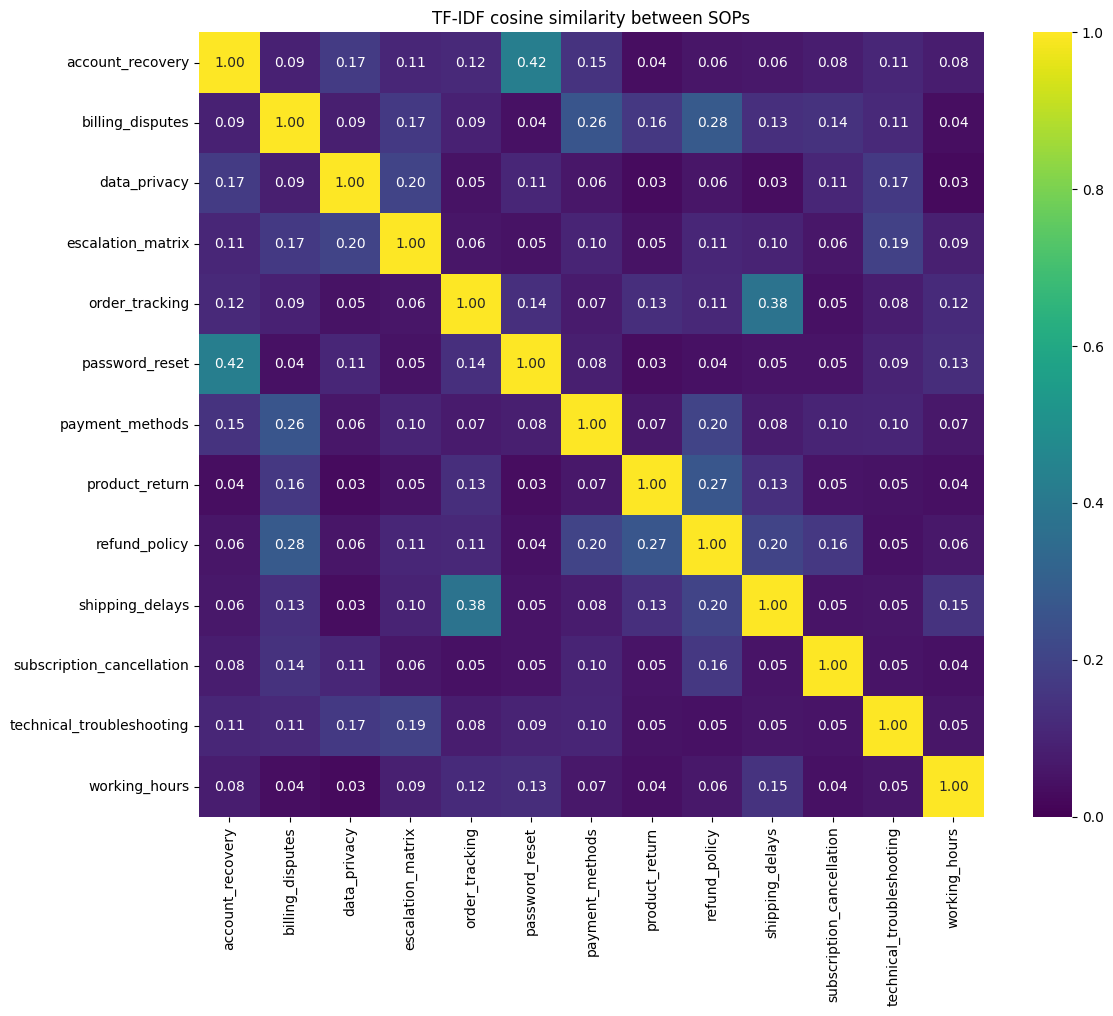

Most similar pairs:
account_recovery  password_reset     0.424
order_tracking    shipping_delays    0.379
billing_disputes  refund_policy      0.278
product_return    refund_policy      0.269
billing_disputes  payment_methods    0.264
dtype: float64
Off-diagonal mean 0.106, max 0.424


In [6]:
from sklearn.metrics.pairwise import cosine_similarity

sim = pd.DataFrame(cosine_similarity(tfidf), index=sop_names, columns=sop_names)

plt.figure(figsize=(12, 10))
sns.heatmap(sim, annot=True, fmt='.2f', cmap='viridis', vmin=0, vmax=1, square=True)
plt.title('TF-IDF cosine similarity between SOPs')
plt.tight_layout()
plt.show()

pairs = sim.where(np.triu(np.ones(sim.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)
print('Most similar pairs:')
print(pairs.head(5).round(3))
print(f'Off-diagonal mean {pairs.mean():.3f}, max {pairs.max():.3f}')

---
## Save Artifacts for Notebook 2

**IMPORTANT:** This cell saves the cleaned DataFrame. Notebook 2 depends on this file.

In [7]:
df.drop(columns=['char_len', 'word_len', 'token_len']).to_csv('sampled_data.csv', index=False)
print(pd.read_csv('sampled_data.csv').shape)

(3902, 5)


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify all items before proceeding to Notebook 2.**

- [ ] Bitext dataset loaded and `.info()` printed
- [ ] Dataset sampled to 4000 rows (or chosen size 1000–5000)
- [ ] Nulls inspected, near-duplicates removed via normalised dedup
- [ ] Top 10 intent bar chart rendered
- [ ] TF-IDF vectorisation completed on SOP documents
- [ ] Cosine similarity heatmap rendered
- [ ] **`sampled_data.csv` saved to disk** ← _CRITICAL for Notebook 2_
- [ ] `corporate_policies/` folder still accessible ← _Needed in Notebooks 2 and 4_

**If any item is unchecked, fix it before moving on.**